In [9]:
# Load and clean dataset
df = preprocessing.load_data(
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

# Create engineered feature
df = preprocessing.create_features(df)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

df.head()

Dataset shape: (7032, 21)
Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,num_services
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,0,3
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,3
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,1


In [10]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5625, 20)
X_test shape: (1407, 20)
y_train shape: (5625,)
y_test shape: (1407,)


In [11]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Create 5 machine learning models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

# Create a full pipeline for each model
model_pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessing.create_preprocessor(df)),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Total models:", len(model_pipelines))
print("\nModels created successfully:")
for name in model_pipelines:
    print("-", name)

Total models: 5

Models created successfully:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- SVM


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, pipeline in model_pipelines.items():
    print(f"Evaluating: {name}")

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results[name] = scores

    print("AUC scores:", scores.round(4))
    print("Mean AUC:", round(scores.mean(), 4))
    print("-" * 40)

Evaluating: Logistic Regression
AUC scores: [0.8468 0.843  0.8374 0.8496 0.853 ]
Mean AUC: 0.8459
----------------------------------------
Evaluating: Decision Tree
AUC scores: [0.6328 0.6235 0.6765 0.6658 0.6507]
Mean AUC: 0.6499
----------------------------------------
Evaluating: Random Forest
AUC scores: [0.8281 0.8113 0.816  0.8274 0.8297]
Mean AUC: 0.8225
----------------------------------------
Evaluating: Gradient Boosting
AUC scores: [0.8428 0.8456 0.8499 0.8524 0.8511]
Mean AUC: 0.8484
----------------------------------------
Evaluating: SVM
AUC scores: [0.8237 0.8226 0.8196 0.8299 0.8381]
Mean AUC: 0.8268
----------------------------------------


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

results = []

for name, pipeline in model_pipelines.items():
    print(f"\nTraining: {name}")

    # Train model on training data
    pipeline.fit(X_train, y_train)

    # Predict on unseen test data
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "CV AUC Mean": cv_results[name].mean(),
        "CV AUC Std": cv_results[name].std(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))


Training: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.70      0.79      1033
       Churn       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407


Training: Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.81      0.81      1033
       Churn       0.48      0.50      0.49       374

    accuracy                           0.73      1407
   macro avg       0.65      0.65      0.65      1407
weighted avg       0.73      0.73      0.73      1407


Training: Random Forest
              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.85      1033
       Churn       0.60      0.47      0.53       374

    accuracy                           0.78      1407
   macro avg       0.71      0.68      0.69    

In [14]:
# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Sort models by mean cross-validation AUC
results_df = results_df.sort_values(
    by="CV AUC Mean",
    ascending=False
).reset_index(drop=True)

# Display rounded results
results_df = results_df.round(4)

results_df

,Model,CV AUC Mean,CV AUC Std,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Gradient Boosting,0.8484,0.0036,0.7960,0.6417,0.5267,0.5786,0.8384
1,Logistic Regression,0.8459,0.0054,0.7257,0.4901,0.7968,0.6069,0.8351
2,SVM,0.8268,0.0066,0.7271,0.4915,0.7727,0.6008,0.8093
3,Random Forest,0.8225,0.0074,0.7775,0.6041,0.4733,0.5307,0.8110
4,Decision Tree,0.6499,0.0197,0.7257,0.4844,0.4973,0.4908,0.6538


In [15]:
best_model_name = results_df.loc[0, "Model"]

print("Best Model:", best_model_name)
print("Mean CV AUC:", results_df.loc[0, "CV AUC Mean"])
print("Test ROC-AUC:", results_df.loc[0, "Test ROC-AUC"])

Best Model: Gradient Boosting
Mean CV AUC: 0.8484
Test ROC-AUC: 0.8384


## Model Evaluation and Conclusion

Five machine learning models were evaluated using
5-fold Stratified Cross-Validation and an unseen test dataset.

The models evaluated were:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. Support Vector Machine (SVM)

Gradient Boosting achieved the highest mean cross-validation
ROC-AUC score of 0.8484 and a test ROC-AUC score of 0.8384.

Therefore, Gradient Boosting was selected as the best model
based on mean cross-validation ROC-AUC.

The model can help identify customers who may be at risk
of leaving the telecom service. Further evaluation of recall,
precision, and the business cost of missed churn cases is
recommended before real-world deployment.

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score

print("ROC curve setup successful!")
print("Models available:", list(model_pipelines.keys()))

ROC curve setup successful!
Models available: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM']


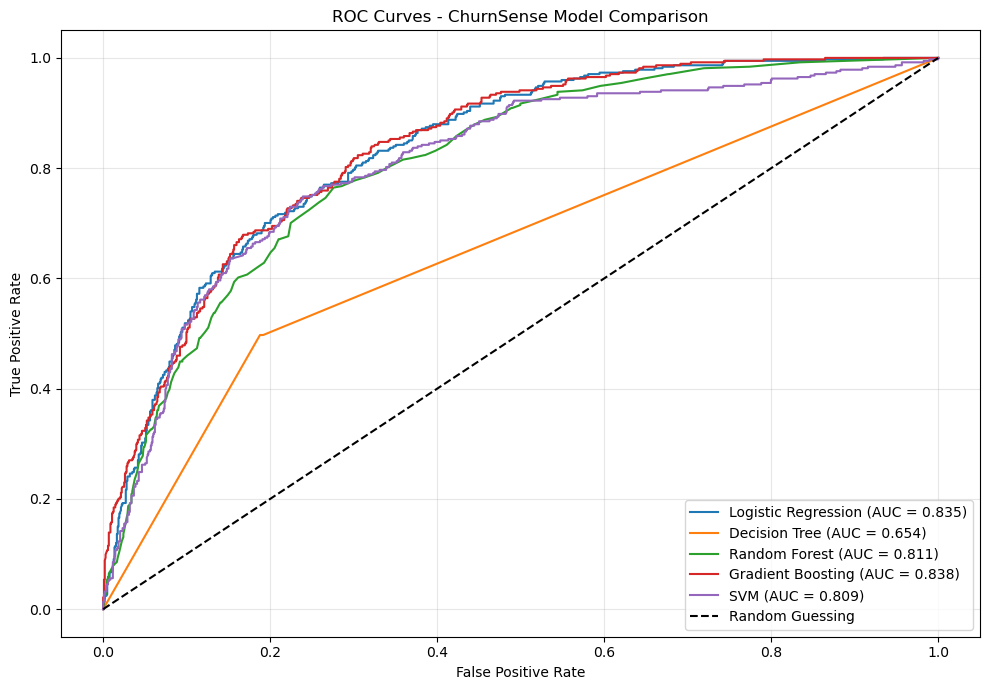

ROC chart saved to reports/roc_curves_all_models.png


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import os

# Create reports folder if it does not exist
os.makedirs("../reports", exist_ok=True)

plt.figure(figsize=(10, 7))

for name, pipeline in model_pipelines.items():

    # Get churn probabilities for test data
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random guessing baseline
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - ChurnSense Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig("../reports/roc_curves_all_models.png", dpi=300)
plt.show()

print("ROC chart saved to reports/roc_curves_all_models.png")

In [18]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from scipy.stats import randint, uniform

print("Tuning libraries imported successfully!")

Tuning libraries imported successfully!


In [19]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Full pipeline: preprocessing + Gradient Boosting
gb_pipeline = Pipeline([
    ("preprocessor", preprocessing.create_preprocessor(df)),
    ("model", GradientBoostingClassifier(random_state=42))
])

# Hyperparameters to test
param_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 0.9, 1.0]
}

cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="roc_auc",
    cv=cv_tuning,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Tune using training data only
random_search.fit(X_train, y_train)

print("Best CV AUC:", round(random_search.best_score_, 4))
print("Best parameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV AUC: 0.8502
Best parameters:
{'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_depth': 3, 'model__learning_rate': 0.05}


Tuned Gradient Boosting Results
Best CV AUC: 0.8502
Test ROC-AUC: 0.8392
Test Accuracy: 0.7939

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1033
       Churn       0.64      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



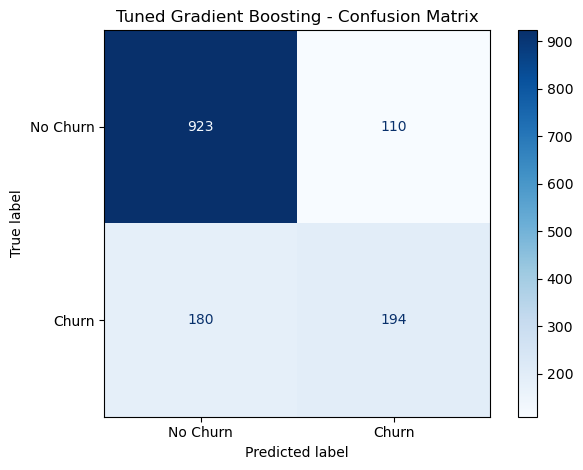

Confusion matrix saved successfully!


In [20]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import os

# Get best tuned model
best_model = random_search.best_estimator_

# Predict on unseen test data
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

# Calculate test metrics
test_auc = roc_auc_score(y_test, y_prob_tuned)
test_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned Gradient Boosting Results")
print("Best CV AUC:", round(random_search.best_score_, 4))
print("Test ROC-AUC:", round(test_auc, 4))
print("Test Accuracy:", round(test_accuracy, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Plot and save confusion matrix
os.makedirs("../reports", exist_ok=True)

cm = confusion_matrix(y_test, y_pred_tuned)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Tuned Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.savefig("../reports/confusion_matrix_tuned_gb.png", dpi=300)
plt.show()

print("Confusion matrix saved successfully!")

In [21]:
%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 6.9 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to 

In [22]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP import successful!")

SHAP version: 0.53.0
SHAP import successful!


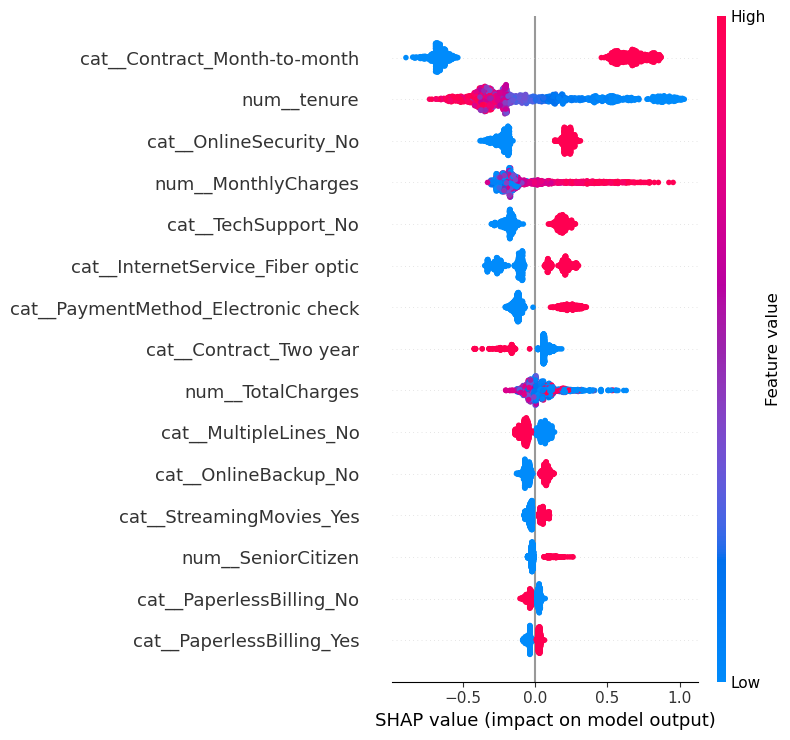

SHAP summary plot saved successfully!


In [23]:
import shap
import matplotlib.pyplot as plt
import os

# Get the best tuned Gradient Boosting model
best_model = random_search.best_estimator_

# Apply preprocessing to the test data
X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test)

# Convert sparse data to dense, if required
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Explain the Gradient Boosting model
explainer = shap.TreeExplainer(best_model.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

# Create and save SHAP summary plot
os.makedirs("../reports", exist_ok=True)

plt.figure()
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    show=False,
    max_display=15
)

plt.tight_layout()
plt.savefig("../reports/shap_summary_plot.png", dpi=300, bbox_inches="tight")
plt.show()

print("SHAP summary plot saved successfully!")

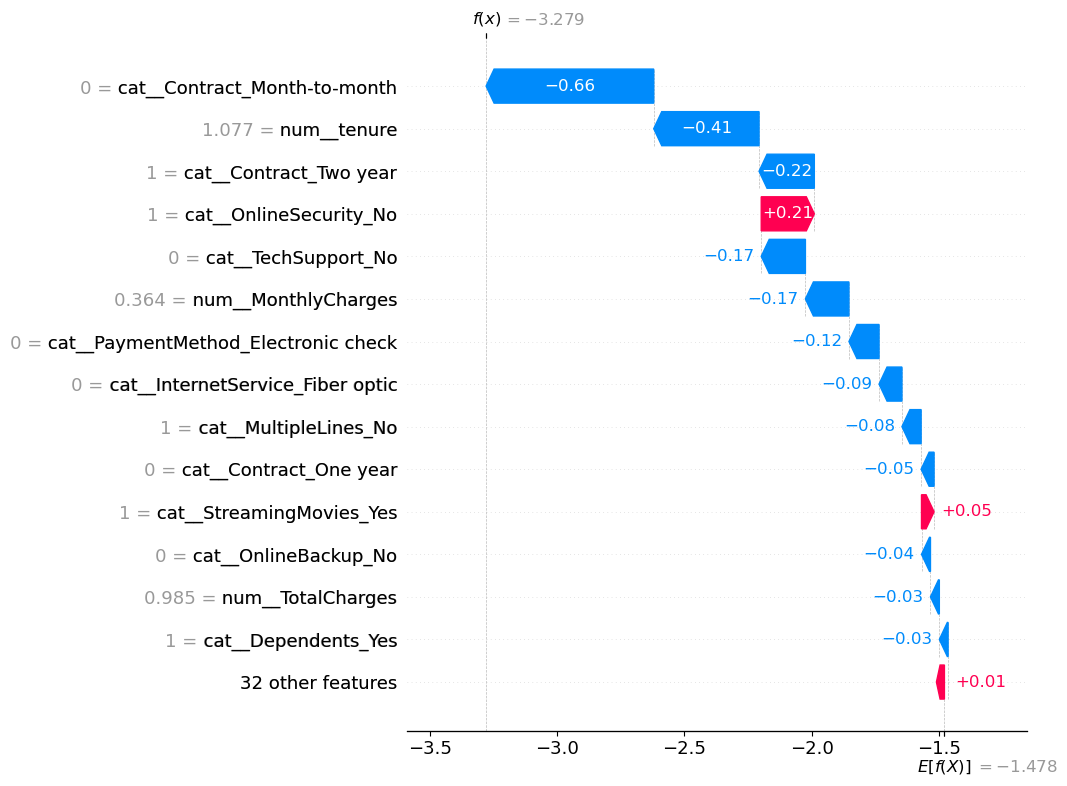

SHAP waterfall plot saved successfully!


In [24]:
import shap
import matplotlib.pyplot as plt
import os
import numpy as np

# Select one customer from the test dataset
customer_index = 0

# Get SHAP values for this customer
base_values = explainer.expected_value

# Handle expected value format
if isinstance(base_values, (list, np.ndarray)):
    base_values = np.array(base_values).flatten()[0]

customer_shap_values = np.array(shap_values)

# Handle different SHAP output formats
if customer_shap_values.ndim == 3:
    customer_values = customer_shap_values[customer_index, :, -1]
else:
    customer_values = customer_shap_values[customer_index]

# Create explanation for one customer
explanation = shap.Explanation(
    values=customer_values,
    base_values=base_values,
    data=X_test_transformed[customer_index],
    feature_names=feature_names
)

# Plot and save waterfall chart
os.makedirs("../reports", exist_ok=True)

shap.plots.waterfall(
    explanation,
    max_display=15,
    show=False
)

plt.savefig(
    "../reports/shap_waterfall_one_customer.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("SHAP waterfall plot saved successfully!")

In [25]:
import os
import joblib

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save the best tuned model
model_path = "../models/churn_model_v1.pkl"
joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("File location:", model_path)
print("Model type:", type(best_model).__name__)

Model saved successfully!
File location: ../models/churn_model_v1.pkl
Model type: Pipeline


In [26]:
import joblib
from sklearn.metrics import roc_auc_score
import os

# Load the saved model
loaded_model = joblib.load("../models/churn_model_v1.pkl")

# Predict using the loaded model
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Calculate test ROC-AUC
loaded_auc = roc_auc_score(y_test, loaded_probabilities)

print("Model loaded successfully!")
print("Loaded Model:", type(loaded_model).__name__)
print("Test ROC-AUC:", round(loaded_auc, 4))
print("Model file exists:", os.path.exists("../models/churn_model_v1.pkl"))

Model loaded successfully!
Loaded Model: Pipeline
Test ROC-AUC: 0.8392
Model file exists: True



# ChurnSense — Model Card

## 1. Model Overview
- **Project:** ChurnSense — Customer Churn Prediction
- **Model:** Tuned Gradient Boosting Classifier
- **Model Version:** v1
- **Task:** Binary classification
- **Target:** Predict whether a telecom customer will churn.

## 2. Dataset
- **Dataset:** Telco Customer Churn
- **Source file:** WA_Fn-UseC_-Telco-Customer-Churn.csv
- **Original records:** 7,043
- **Records after cleaning:** 7,032
- **Training samples:** 5,625
- **Testing samples:** 1,407

## 3. Preprocessing
- Removed customerID.
- Converted TotalCharges to numeric format.
- Removed records with missing TotalCharges.
- Encoded Churn as 1 (Yes) and 0 (No).
- Applied StandardScaler to numeric features.
- Applied OneHotEncoder to categorical features.
- Used a stratified train-test split.

## 4. Model Selection and Tuning
Gradient Boosting was selected because it achieved the highest
mean cross-validation ROC-AUC among the five baseline models.

RandomizedSearchCV with 5-fold stratified cross-validation
was used to tune the model.

Best cross-validation ROC-AUC: 0.8502

## 5. Evaluation
- **Test ROC-AUC:** Record the actual score from the notebook.
- **Test Accuracy:** Record the actual score from the notebook.
- **Additional evaluation:** Classification report, confusion matrix,
  and ROC curve.
- **Explainability:** SHAP summary and individual-customer waterfall plots.

## 6. Intended Use
This model can support analysis of customers who may be at risk
of leaving a telecom service. It can help teams investigate
retention opportunities.

## 7. Limitations
- Performance may change on new customer data.
- Predictions are estimates, not guarantees.
- The model should be evaluated on fresh data before real-world use.
- Business decisions should consider customer context and model errors.

## 8. Saved Model
- **File:** models/churn_model_v1.pkl
- **Format:** Joblib-serialized scikit-learn Pipeline

## 9. Model Choice Justification
The tuned Gradient Boosting model achieved a mean CV ROC-AUC of
0.8502. This indicates good ability to distinguish churners from
non-churners during cross-validation. Final selection should also
consider its held-out test performance and the business cost of
false positives and false negatives.